# 29 · Why multi-agent, and when one agent is better
Level L5 · Part 5 · core · ~25 min · builds on 12, 19, 22

## Goal
Build the same two-part task two ways: one agent that holds every tool, and two specialist agents behind a router. Count the model calls and the
tokens each build uses, and the number of tools each agent has to choose from. Then decide, with the numbers, whether the second agent pays.

## Why it matters
A second agent is not free. It is a second prompt, a second loop and usually a router: every extra model call adds time, and each agent
carries a prompt and tool list of its own. The reason to split is real: the tools are too many for one agent to choose from well, two jobs
need different rules, or they must run in separate places.

| One agent | Specialists behind a router |
|---|---|
| One prompt, one loop, one bill | Several prompts, a router, and a bill for each |
| Chooses from every tool at once | Each specialist chooses from a few tools |
| One failure stops the whole task | One specialist can fail while the other answers |

**What it makes easy:** a clear reason for each agent, and a cost you can see. **When you don't need it:** a task that one agent finishes with a
few tool calls, which is the common case.

## The idea
A **multi-agent** system is more than one agent with a loop, plus a rule for who does what. The two common shapes are a **router** (one agent
picks a specialist) and a **supervisor** (one agent gives work to several and merges it). Each extra agent adds at least one model call, so the
split must save more than it costs.

## Picture
`show_mermaid` is a course helper (in `graph_view.py`) that draws a Mermaid diagram from text. The diagram shows both builds before we measure them.

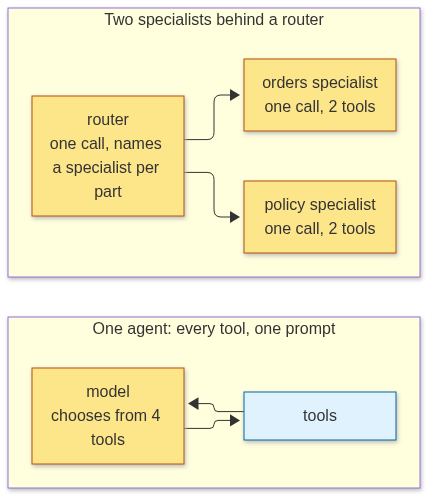

In [1]:
import sys; sys.path.insert(0, "../../..")  # the topic folder: llm_setup.py, graph_view.py and tut_env.py live there

from graph_view import show_mermaid

show_mermaid("""
flowchart LR
  subgraph ONE["One agent: every tool, one prompt"]
    o1["model<br/>chooses from 4 tools"] --> o2["tools"] --> o1
  end
  subgraph MULTI["Two specialists behind a router"]
    r1["router<br/>one call, names a specialist per part"] --> s1["orders specialist<br/>one call, 2 tools"]
    r1 --> s2["policy specialist<br/>one call, 2 tools"]
  end
  classDef model fill:#fde68a,stroke:#b45309
  classDef code fill:#e0f2fe,stroke:#0369a1
  class o1,r1,s1,s2 model
  class o2 code
""")

## Step by step

**Step 1 · the tools and the question (no call).** Four tools in all: two about orders and two about policy. The question has two parts, and
each part needs one of the specialists. Both builds below answer the same question, so the difference is the number of agents.

In [2]:
import json
from pathlib import Path

from langchain_core.tools import tool
from pydantic import BaseModel, ConfigDict, Field

ORDERS = json.loads((Path("../../../data") / "support_eval.json").read_text())["world"]["orders"]
QUESTION = "Order 1003 never arrived. What is its status, and what does the policy say about lost parcels?"


class OrderQuery(BaseModel):
    model_config = ConfigDict(extra="forbid")
    order_id: str = Field(description="The order number the customer wrote: four digits, such as 1003.", pattern=r"^\d{4}$")


print("question:", QUESTION)

question: Order 1003 never arrived. What is its status, and what does the policy say about lost parcels?


The four tools: two read order facts, two read the desk's policy. A tool is a Python function the model may ask to run; the `@tool` decorator
turns it into something the model can see and call.

In [3]:
@tool(args_schema=OrderQuery)
def order_status(order_id: str) -> dict:
    """Look up one order's status and days late."""
    return ORDERS.get(order_id, {"error": f"no order {order_id}"})


@tool(args_schema=OrderQuery)
def order_total(order_id: str) -> dict:
    """Look up one order's total paid."""
    row = ORDERS.get(order_id, {})
    return {"order_id": order_id, "total": row.get("total")}


@tool
def policy_lost_parcel() -> str:
    """The desk's policy for a parcel that never arrives."""
    return "After 10 working days from dispatch, contact the desk; we trace the parcel or send a replacement or refund."


@tool
def policy_returns() -> str:
    """The desk's returns policy: 30 days, unused, original packaging."""
    return "Returns within 30 days of delivery, unused, in original packaging. Refunds are approved by a person."


ORDER_TOOLS = [order_status, order_total]
POLICY_TOOLS = [policy_lost_parcel, policy_returns]
print("order tools:", [t.name for t in ORDER_TOOLS], "| policy tools:", [t.name for t in POLICY_TOOLS])

order tools: ['order_status', 'order_total'] | policy tools: ['policy_lost_parcel', 'policy_returns']


**Step 2 · one agent with all four tools (model calls counted).** `llm_replay` is a course helper: it records each model answer the first time,
and replays the saved answer later, so the lesson runs offline. `get_llm()` is the course's model setup, the same one lesson 02 uses. Each reply
carries its token counts, which we add up here.

In [4]:
import llm_replay
llm_replay.start("29_why-multi-agent")

from langchain.agents import create_agent
from langchain_core.messages import HumanMessage, SystemMessage
from llm_setup import get_llm

llm = get_llm()
PRICE_IN, PRICE_OUT = 0.25, 1.50  # USD per 1M tokens, the same as lesson 02


def tokens_of(messages) -> tuple[int, int]:
    tin = tout = 0
    for m in messages:
        u = getattr(m, "usage_metadata", None) or {}
        tin += u.get("input_tokens", 0)
        tout += u.get("output_tokens", 0)
    return tin, tout

LLM mode: replay (29_why-multi-agent.yaml)


Gemini on Vertex AI · API key loaded: True


The one agent runs its loop: the model asks for tools, reads the results, and answers. Two model calls is the normal shape for this question.

In [5]:
one = create_agent(model=llm, tools=ORDER_TOOLS + POLICY_TOOLS,
                   system_prompt="You are the Brightside desk. Use the tools for order facts and policy.")
single = one.invoke({"messages": [HumanMessage(content=QUESTION)]}, config={"recursion_limit": 8})
single_calls = sum(m.type == "ai" for m in single["messages"])  # one AI message per model call
single_in, single_out = tokens_of(single["messages"])
print("one agent:", single["messages"][-1].text[:160])

one agent: Order 1003 is currently marked as lost and is 9 days late.

Regarding our policy for lost parcels, if a parcel has not arrived after 10 working days from dispat


**Step 3 · two specialists behind a router (model calls counted).** The router is one call: it reads the whole question once and names the
specialist for each part. Each specialist then gets one call. It picks one of its own tools, and the tool's result is that part's answer.
`bind_tools` is a LangChain method that attaches a list of tools to a model, so the model can ask for them. The specialists return the tool's
result, not a written sentence, so this comparison counts calls and tokens; it does not judge the wording.

In [6]:
import re

SPECIALIST_TOOLS = {"orders": ORDER_TOOLS, "policy": POLICY_TOOLS}
SPECIALIST_PROMPT = {"orders": "You answer order questions with the order tools only.",
                     "policy": "You answer policy questions with the policy tools only."}
ROUTER_PROMPT = ("Two parts of one customer question follow. For each part, name the specialist that owns it: "
                 "'orders' or 'policy'. Reply with the two names, separated by a comma, in order.")


def route(parts: list[str]) -> tuple[list[str], dict]:
    reply = llm.invoke(ROUTER_PROMPT + "\n" + "\n".join(f"{i}. {p}" for i, p in enumerate(parts, 1)))
    return re.findall(r"orders|policy", reply.text.lower()), reply.usage_metadata

A specialist call returns a tool request. The code runs that tool and keeps the result as the part's answer. If the model answers in plain text
instead, we keep the text.

In [7]:
def answer(name: str, question: str) -> tuple[str, dict]:
    reply = llm.bind_tools(SPECIALIST_TOOLS[name]).invoke(
        [SystemMessage(content=SPECIALIST_PROMPT[name]), HumanMessage(content=question)])
    if not reply.tool_calls:
        return reply.text, reply.usage_metadata
    call = reply.tool_calls[0]
    tools = {t.name: t for t in SPECIALIST_TOOLS[name]}
    return str(tools[call["name"]].invoke(call["args"])), reply.usage_metadata

Now the router runs once for the question, and each part goes to its specialist. The token counts add up the router's reply and the specialists'.

In [8]:
parts = ["What is the status of order 1003?", "What does the policy say about lost parcels?"]
names, router_usage = route(parts)
multi_in, multi_out = router_usage["input_tokens"], router_usage["output_tokens"]
replies = []
for name, question in zip(names, parts):
    text, usage = answer(name, question)
    replies.append((name, text))
    multi_in += usage["input_tokens"]
    multi_out += usage["output_tokens"]
multi_calls = 1 + len(replies)  # the router's reply, then one reply per specialist
llm_replay.stop()  # the last model call of this lesson
print("router sent the parts to:", names)
print("specialists:", [(n, t[:70]) for n, t in replies])

router sent the parts to: ['orders', 'policy']
specialists: [('orders', "{'status': 'lost', 'days_late': 9, 'total': 89.5}"), ('policy', 'After 10 working days from dispatch, contact the desk; we trace the pa')]


**Step 4 · the comparison (no call).** The table reads the counts above. Each choice sees only the tools of its agent, so the number of tools
is printed too. The cost is the input and output tokens at the prices above.

In [9]:
def cost(tin: int, tout: int) -> float:
    return (tin * PRICE_IN + tout * PRICE_OUT) / 1_000_000


print(f"{'build':<26}{'model calls':>12}{'tools per choice':>20}{'input tokens':>15}{'cost, USD':>14}")
print(f"{'one agent':<26}{single_calls:>12}{len(ORDER_TOOLS + POLICY_TOOLS):>20}{single_in:>15}{cost(single_in, single_out):>14.6f}")
print(f"{'router + 2 specialists':<26}{multi_calls:>12}{'2 (each specialist)':>20}{multi_in:>15}{cost(multi_in, multi_out):>14.6f}")
print("tokens are read from every reply: the router's and the specialists'")

build                      model calls    tools per choice   input tokens     cost, USD
one agent                            2                   4            449      0.000310
router + 2 specialists               3 2 (each specialist)            255      0.000118
tokens are read from every reply: the router's and the specialists'


## At work
- Teams start with one agent and split when a measured problem appears: wrong tool choices, or a tool list that no longer fits in one prompt →
  lesson 30 (supervisor and hand-offs).
- Each agent is a budget. Teams count the calls per task and cap them, because a router adds a call to every question → lesson 36 (cost and latency).
- A split by permission is a security decision: a specialist that may refund is a different agent from one that may only read → lesson 34.

## What just happened
- The one agent made **2** model calls, read **449** input tokens and cost **$0.000310**; it chose from **4** tools at each step.
- The router and two specialists made **3** calls (1 router + 1 per specialist), read **255** input tokens and cost **$0.000118**; each choice saw **2** tools.
- The split adds one call but costs less than half as much here: the one agent sends all four tool descriptions on both of its calls.
- That saving does not show the split is better: the specialists return tool results, not written answers. The split pays when the tool list is too long for one agent, two jobs need different rules or permissions, or one part runs on another team's system.

## Common mistakes
1. **Splitting before measuring.** A second agent that does not fix a measured failure only adds cost.
2. **Forgetting the router's call.** The router is a model call on every question. Count it.
3. **Two agents with the same tools.** If the tools overlap, the split gives no clear owner. Give each tool one owner.

## Production checklist
- [ ] Count the model calls and tokens per task for each build, on the same questions.
- [ ] Split only when a measured failure (wrong tool, a tool list too long, different permissions) needs it.
- [ ] Give each tool one owner agent, so the split has a clear owner.
- [ ] Cap the steps of each agent (`recursion_limit`), so a loop cannot run on.

## Try it
Write `multi_agent_calls(questions, specialists_per_question)` that returns the number of model calls when each question has one router call and one
call per specialist. Test it on `(1, 1)` and `(3, 2)`. No model call is needed.

In [10]:
# your code here

**Answer** — try it first, then expand the hidden cell below.

In [11]:
def multi_agent_calls(questions: int, specialists_per_question: int) -> int:
    return questions * (1 + specialists_per_question)


print(multi_agent_calls(1, 1), multi_agent_calls(3, 2))  # 2 9

2 9


## Key terms
- **Multi-agent system** — more than one agent with a rule for who does what.
- **Router** — a model call that names which specialist answers each part.
- **Specialist** — an agent with a few tools for one kind of job.
- **Supervisor** — one agent that gives work to several agents and merges their results.
- **Model call** — one request to the model; the unit this lesson counts.

## Recap
- A second agent adds at least one call per question: the router, and one per specialist.
- Split when a measured problem needs it: too many tools, different permissions, or a part that runs elsewhere.
- Count both builds before you decide.

**Interview:** "Would you split this support agent into several agents?" Strong answer: "Only if the measured problem needs it. I would count the calls and
the tool choices for both builds on the same questions. A split that does not fix a measured failure only adds a router and a bill."